<a href="https://colab.research.google.com/github/jorgecaraveobalderas-beep/Class-Files/blob/main/PracticaRegresionLinealMultiple_274702.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Jorge Alberto Caraveo Balderas
*   Matrícula: 274702

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [ ]:
#1 Importa las bibliotecas necesarias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import statsmodels.api as sm


#2 Carga el archivo advertising.csv

df = pd.read_csv('advertising.csv')

#3 Muestra las primeras filas del dataframe
print("Primeas 5 filas")
print(df.head())

#4 Describe estadísticamente las variables
print()
print("Descripcion estadistico de las variables")
print(df.describe())


Primeas 5 filas
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9

Descripcion estadistico de las variables
               TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   15.130500
std     85.854236   14.846809   21.778621    5.283892
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   11.000000
50%    149.750000   22.900000   25.750000   16.000000
75%    218.825000   36.525000   45.100000   19.050000
max    296.400000   49.600000  114.000000   27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

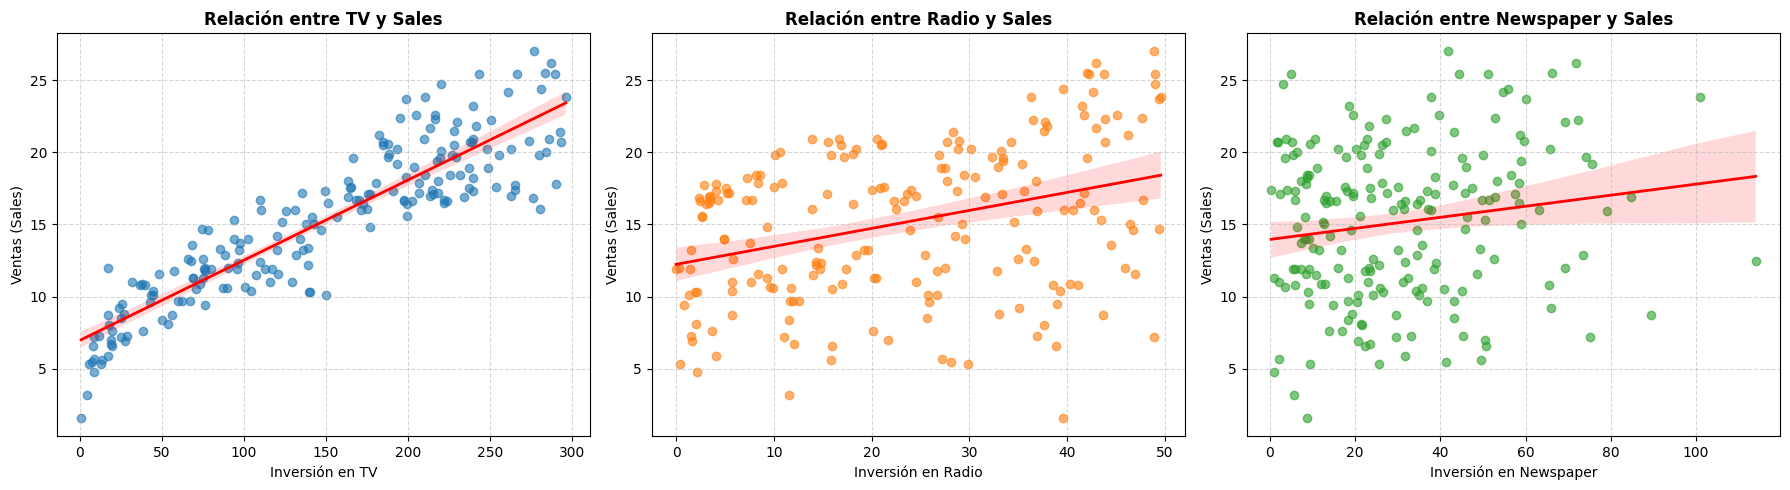

In [ ]:
#1 Grafica dispersión entre cada variable independiente (TV, Radio, Newspaper) y Sales. Usa también regplot

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
variables_indep = ['TV', 'Radio', 'Newspaper']
colores = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i, (var, color) in enumerate(zip(variables_indep, colores)):
  sns.regplot(data=df, x=var, y='Sales', ax=axes[i], color=color, scatter_kws={'alpha': 0.6}, line_kws={'color': 'red', 'linewidth': 2})

  axes[i].set_title(f'Relación entre {var} y Sales', fontsize=12, fontweight='bold')
  axes[i].set_xlabel(f'Inversión en {var}')
  axes[i].set_ylabel('Ventas (Sales)')
  axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


**2.1.2 Interpreta visualmente la relación entre variables.**


* **TV vs. Sales:** Se observa una relación lineal positiva fuerte y clara. A medida que incrementa la inversión en publicidad en televisión, las ventas suben de forma consistente desde 5 hasta más de 25 unidades. Los puntos se mantienen cercanos a la línea roja de regresión y la banda de confianza es estrecha, lo que indica que `TV` es un buen predictor lineal
* **Radio vs. Sales:** Existe una relación lineal positiva moderada. Aunque la recta de regresión tiene pendiente ascendente, los puntos presentan una mayor dispersión vertical alrededor de la línea en comparación con `TV`, lo que sugiere que la radio influye positivamente pero con mayor variabilidad
* **Newspaper vs. Sales:** Se aprecia una relación lineal muy débil o casi nula. La nube de puntos verdes está completamente dispersa sin seguir un patrón claro, la pendiente de la recta roja es casi plana indicando que la inversión en periódico por sí sola no explica de forma lineal el comportamiento de las ventas

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

Matriz de correlación:
                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.901208
Radio      0.054809  1.000000   0.354104  0.349631
Newspaper  0.056648  0.354104   1.000000  0.157960
Sales      0.901208  0.349631   0.157960  1.000000


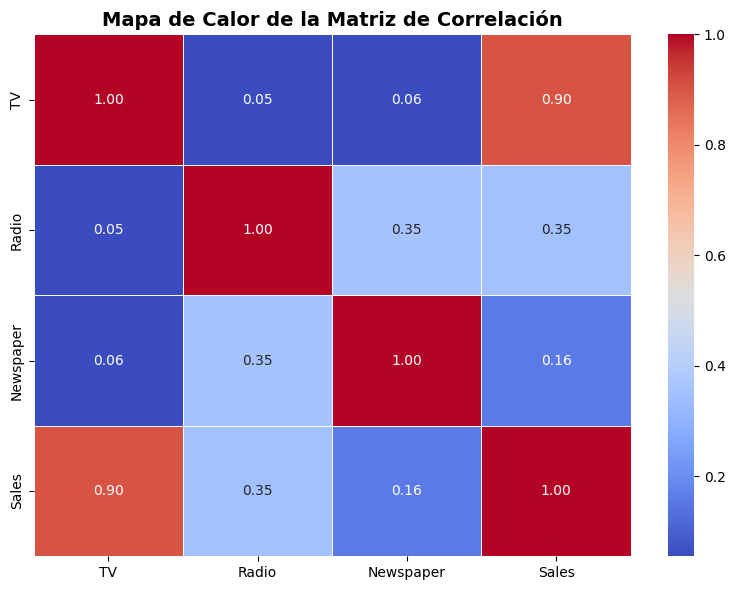

In [ ]:
# 1 Calcula la matriz de correlación

corr_matrix = df.corr()
print(f"Matriz de correlación:\n{corr_matrix}")


# 2 Visualízala con un heatmap

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Mapa de Calor de la Matriz de Correlación', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**2.2.3 Responde: ¿Qué variables están más correlacionadas con Sales? ¿Hay correlación alta entre predictores?**

* **Variables más correlacionadas con `Sales`:** La variable que presenta una mayor correlación lineal con las ventas es **`TV`** con un coeficiente de 0.90 , lo que indica una relación positiva fuerte. En segundo lugar se encuentra **`Radio`** con una correlación positiva moderada de 0.35 , mientras que **`Newspaper`** tiene una correlación muy baja de apenas 0.16, confirmando que el gasto en periódico tiene poca asociación lineal directa con las ventas
* **Correlación entre predictores (Multicolinealidad):** **No hay correlación alta entre las variables predictoras.** Las correlaciones entre `TV` y `Radio` 0.05 y entre `TV` y `Newspaper` 0.06 son prácticamente nulas. La correlación más alta entre variables independientes ocurre entre **`Radio` y `Newspaper`** con 0.35, un valor bajo que está lejos de representar un problema de multicolinealidad. Por lo tanto, los predictores aportan información independiente al modelo

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

Factor de Inflación de la Varianza (VIF) por predictor:
    Variable       VIF
0         TV  1.004611
1      Radio  1.144952
2  Newspaper  1.145187


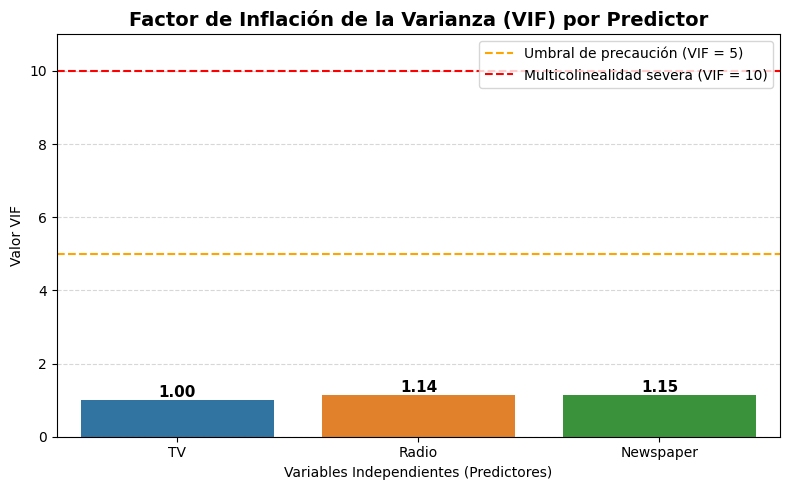

In [ ]:

# 1 Calcula el VIF (Variance Inflation Factor) para cada predictor

X_vif = add_constant(df[['TV', 'Radio', 'Newspaper']])
vif_data = pd.DataFrame()
vif_data['Variable'] = X_vif.columns
vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]


# Filtramos la constante para quedarnos solo con los predictores

vif_predictores = vif_data[vif_data['Variable'] != 'const'].reset_index(drop=True)
print("Factor de Inflación de la Varianza (VIF) por predictor:")
print(vif_predictores)


#2 Crea un diagrama de barras para mostrar el VIF
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=vif_predictores,
    x='Variable',
    y='VIF',
    hue = "Variable",
    palette=['#1f77b4', '#ff7f0e', '#2ca02c']
)
plt.axhline(y=5, color='orange', linestyle='--', linewidth=1.5, label='Umbral de precaución (VIF = 5)')
plt.axhline(y=10, color='red', linestyle='--', linewidth=1.5, label='Multicolinealidad severa (VIF = 10)')
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.title('Factor de Inflación de la Varianza (VIF) por Predictor', fontsize=14, fontweight='bold')
plt.ylabel('Valor VIF')
plt.xlabel('Variables Independientes (Predictores)')
plt.ylim(0, 11)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



**3.3 Interpreta si hay multicolinealidad:
¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
¿Qué implicaciones tiene esto para el modelo?**


* **¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?**
  **No.** Ninguna de las variables predictoras supera el umbral de precaución (VIF > 5) ni el de multicolinealidad severa (VIF > 10). Todos los valores se encuentran prácticamente en el mínimo ideal de $1.0$: **`TV`** tiene un VIF de 1.00, **`Radio`** de 1.14y **`Newspaper`** de 1.15
* **¿Qué implicaciones tiene esto para el modelo?**
  La ausencia total de multicolinealidad tiene implicaciones positivas para nuestro modelo de regresión lineal múltiple:
  1. **Interpretación clara de cada varible:** Podemos evaluar e interpretar el impacto individual de cada canal publicitario (`TV`, `Radio` y `Newspaper`) sobre las ventas (`Sales`) de forma independiente, sin que uno afecte al otro.
  2. **Conservación de variables:** No es necesario descartar ni combinar ninguna variable por problemas de redundancia antes de entrenar el modelo.

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [ ]:
#1 Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes

X= df[['TV', 'Radio', 'Newspaper']]
y= df['Sales']

# División 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
modelo = LinearRegression()
modelo.fit(X_train, y_train)

#2 Imprime el intercepto y los coeficientes del modelo
print(f"Intercepto (B0): {modelo.intercept_:.4f}")
print()

coeficientes = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente (B)': modelo.coef_
})
print("Coeficientes del modelo:")
print(coeficientes)

Intercepto (B0): 4.7141

Coeficientes del modelo:
    Variable  Coeficiente (B)
0         TV         0.054509
1      Radio         0.100945
2  Newspaper         0.004337


**4.1.3.Interpreta cada uno: ¿Qué significa cada uno de los coeficientes en términos de ventas?**

* **Intercepto (B0 = 4.7141):** Representa el volumen base estimado de ventas (**$4.7141$ unidades**) cuando no se invierte nada en publicidad (TV = 0, Radio = 0, Newspaper = 0)
* **Coeficiente de `TV` (B1 = 0.054509):** Manteniendo constante la inversión en `Radio` y `Newspaper`, por cada unidad adicional invertida en publicidad de **`TV`**, las ventas aumentan en promedio 0.0545 unidades
* **Coeficiente de `Radio` (B2 = 0.100945):** Manteniendo constante el gasto en `TV` y `Newspaper`, por cada unidad adicional invertida en **`Radio`**, las ventas incrementan en promedio 0.1009 unidades. Es el medio con mayor retorno marginal por unidad invertida
* **Coeficiente de `Newspaper` (B3 = 0.004337):** Manteniendo constantes `TV` y `Radio`, por cada unidad adicional invertida en **`Newspaper`**, las ventas suben apenas 0.0043 unidades. Su efecto sobre las ventas es minimo frente a los otros dos canales

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

Primeros 5 residuos calculados:
0    0.727460
1   -0.902524
2    1.414392
3   -0.895018
4    1.987127
Name: Sales, dtype: float64

Media de los residuos: -0.0797


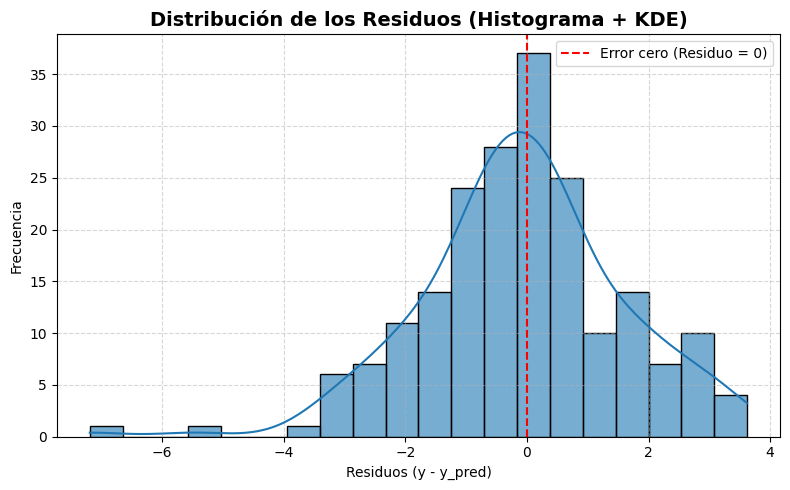

In [ ]:
# Calcula los residuos: residuos = y - y_pred
y_pred = modelo.predict(X)
residuos = y - y_pred
print("Primeros 5 residuos calculados:")
print(residuos.head())
print(f"\nMedia de los residuos: {residuos.mean():.4f}")

# Grafica un histograma con KDE de los residuos
plt.figure(figsize=(8,5))
sns.histplot(
    residuos, kde=True, color='#1f77b4', bins=20, edgecolor='black', alpha=0.6
)
plt.axvline(
    x=0,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Error cero (Residuo = 0)',
)
plt.title(
    'Distribución de los Residuos (Histograma + KDE)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Residuos (y - y_pred)')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**4.2.3 ¿Los residuos parecen distribuirse normalmente?**

* **Comportamiento general cercano a la normal:** Sí, en su parte central los residuos muestran una distribución aproximadamente normal y se encuentran centrados prácticamente en cero, con una media de -0.0797 y la gran mayoría de los errores concentrados entre -2 y +2 unidades de `Sales`.

* **Ligero sesgo negativo por valores atípicos:** Se aprecia una asimetría hacia la izquierda, ocasionada por un par de observaciones atípicas cercanas a -5.5 y -7$, en las cuales el modelo sobreestimó las ventas reales. No obstante, al tratarse de casos aislados y mantener simetría alrededor de cero en el grueso de los datos, se cumple de forma aceptable el supuesto de normalidad de los residuos.


### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

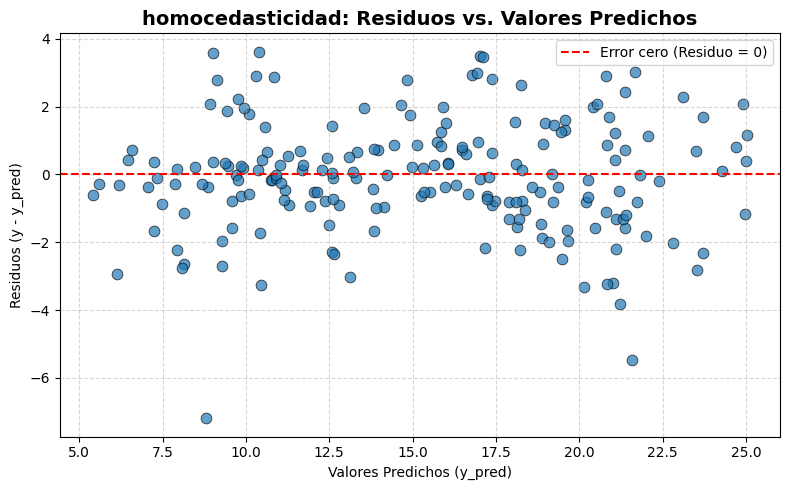

In [ ]:
# Grafica los residuos contra los valores predichos
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=y_pred, y=residuos, color='#1f77b4', alpha=0.7, edgecolor='black', s=60)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Error cero (Residuo = 0)',)

plt.title('homocedasticidad: Residuos vs. Valores Predichos', fontsize=14, fontweight='bold')
plt.xlabel('Valores Predichos (y_pred)')
plt.ylabel('Residuos (y - y_pred)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**4.3.2 ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?**


* Varianza relativamente acotada: La gran mayoría de los residuos se distribuyen dentro de una franja horizontal constante entre -2 y +2 alrededor de la línea roja, sin mostrar un patrón clásico de cono donde el error crezca descontroladamente a medida que aumentan las ventas predichas
* Valores atípicos: La dispersión no es completamente aleatoria; un par de valores atípicos negativos cercanos a -5.5 y -7. Esto sugiere que, aunque el modelo lineal funciona bien, existe una ligera relación no lineal entre medios publicitarios


### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

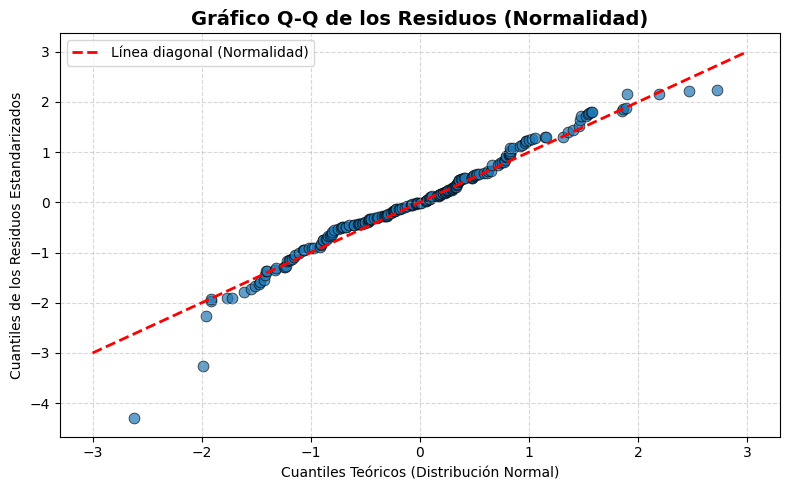

In [ ]:
# Graficar el Q-Q Plot
residuos_ordenados = np.sort(residuos)
residuos_estandarizados = (
    residuos_ordenados - residuos.mean()
) / residuos.std()
np.random.seed(42)
cuantiles_teoricos = np.sort(np.random.normal(0, 1, len(residuos)))

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=cuantiles_teoricos,
    y=residuos_estandarizados,
    color='#1f77b4',
    alpha=0.7,
    edgecolor='black',
    s=60,
)
plt.plot(
    [-3, 3],
    [-3, 3],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Línea diagonal (Normalidad)',
)

plt.title(
    'Gráfico Q-Q de los Residuos (Normalidad)', fontsize=14, fontweight='bold'
)
plt.xlabel('Cuantiles Teóricos (Distribución Normal)')
plt.ylabel('Cuantiles de los Residuos Estandarizados')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**4.4.2 Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.**


* a) Alineación sobre la línea diagonal: Entre los cuantiles teóricos de -2 y +2, los puntos se alinean de manera muy estrecha sobre la línea diagonal roja de referencia, lo que demuestra que el cuerpo de los residuos sigue una distribución normal
* b) Desviaciones en los extremos: En el extremo inferior izquierdo (para cuantiles teóricos menores a -2), se observa que un par de puntos se desvían hacia abajo de la diagonal, mientras que en el extremo superior derecho (arriba de +2) se aplanan ligeramente cerca de +2.2. Esto confirma la presencia de una leve asimetría negativa provocada por casos aislados donde el modelo sobreestimó las ventas (`Sales`), sin que ello invalide el supuesto general de normalidad

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [ ]:
# Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print("Métricas de Evaluación del Modelo:")
print(f"a) MSE (Error Cuadrático Medio): {mse:.4f}")
print(f"b) RMSE (Raíz del Error Cuadrático Medio): {rmse:.4f}")
print(
    f"c) R² (Coeficiente de Determinación): {r2:.4f} ({r2 * 100:.2f}% de"
    " varianza explicada)"
)

Métricas de Evaluación del Modelo:
a) MSE (Error Cuadrático Medio): 2.7225
b) RMSE (Raíz del Error Cuadrático Medio): 1.6500
c) R² (Coeficiente de Determinación): 0.9020 (90.20% de varianza explicada)


**4.5.2 ¿Qué nos dicen estas métricas sobre el ajuste del modelo?**


* R² = 0.90: El coeficiente de determinación indica que el modelo de regresión lineal múltiple (utilizando `TV`, `Radio` y `Newspaper`) logra explicar aproximadamente el 90% de la variabilidad total en las ventas (`Sales`). Esto demuestra un ajuste global bueno, ya que solo cerca del 10% de la variación depende de factores externos no incluidos en el modelo
* Magnitud del error de predicción (`MSE` y `RMSE`): El `MSE` (2.72) mide el promedio de los errores al cuadrado, mientras que el `RMSE` (1.65) expresa ese error en las mismas unidades originales de la variable dependiente (`Sales`).Considerando que las ventas oscilan entre 1.6 y 27 unidades, equivocarse en promedio por apenas +-1.65 unidades confirma que el modelo tiene una buena precisión predictiva

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

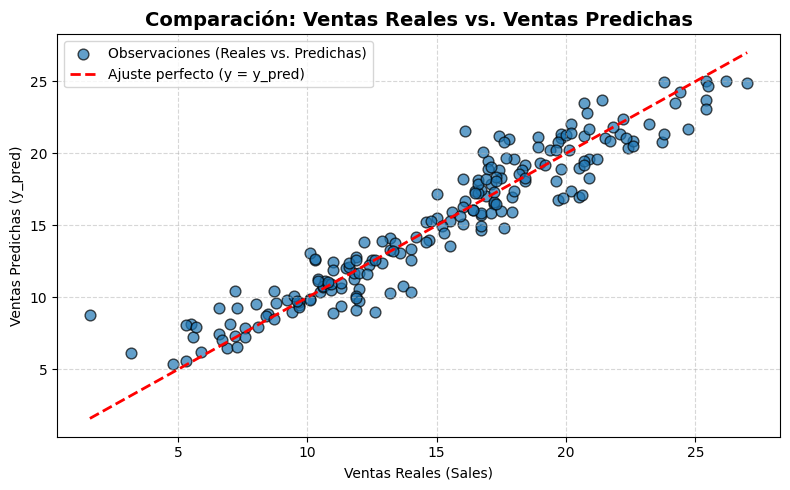

In [ ]:
# Crea un gráfico comparando Sales reales vs Sales predichas

plt.figure(figsize=(8, 5))
plt.scatter(
    y,
    y_pred,
    color='#1f77b4',
    alpha=0.7,
    edgecolors='black',
    s=60,
    label='Observaciones (Reales vs. Predichas)',
)

lim_min = min(y.min(), y_pred.min())
lim_max = max(y.max(), y_pred.max())
plt.plot(
    [lim_min, lim_max],
    [lim_min, lim_max],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Ajuste perfecto (y = y_pred)',
)

plt.title(
    'Comparación: Ventas Reales vs. Ventas Predichas',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Ventas Reales (Sales)')
plt.ylabel('Ventas Predichas (y_pred)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**4.6.3 .¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?**

* Ajuste lineal fuerte y consistente: Se observa que la gran mayoría de los puntos azules se agrupan de forma estrecha a lo largo de la línea diagonal roja punteada, especialmente en el rango de 5 a 24 unidades. Esto confirma visualmente el poder predictivo del modelo, indicando que las predicciones son  cercanas a las ventas reales
* Identificación de valores atípicos: En el extremo inferior izquierdo se distinguen dos observaciones atípicas, ubicándose por encima de la línea roja. Estos dos puntos corresponden a los residuos negativos extremos  detectados antes en el histograma y en el Q-Q Plot


### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [ ]:
# Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
X_train_sm = add_constant(X_train)
modelo_sm = sm.OLS(y_train, X_train_sm).fit()
print(modelo_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.898
Method:                 Least Squares   F-statistic:                     468.7
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           8.51e-78
Time:                        01:17:33   Log-Likelihood:                -305.78
No. Observations:                 160   AIC:                             619.6
Df Residuals:                     156   BIC:                             631.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.7141      0.352     13.407      0.0


**4.7.2 ¿Qué variables tienen p-value menores a 0.05?**

**4.7.3 ¿Cuál es la conclusión sobre esas variables?**


* ¿Qué variables tienen p-value menores a 0.05?: Las variables predictoras `TV` y `Radio` tienen un `p-value < 0.05`. La variable `Newspaper` (0.537) supera  dicho umbral de significancia
* Se concluye que `TV` y `Radio` tienen un efecto estadísticamente significativo y real sobre las ventas (`Sales`), por lo que deben mantenerse en el modelo. Por el contrario, para `Newspaper` la inversión en periódico no aporta información estadísticamente significativa cuando ya se consideran `TV` y `Radio`, de modo que puede descartarse para obtener un modelo más preciso sin perder capacidad predictiva

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

- **Para la Parte 5, la variable a descartar es Newspaper. Aunque en el análisis VIF ninguna superó el umbral de 5, en el paso 4.7 se confirma que Newspaper tiene un p-valor=0.537 y era la única que presentaba cierta correlación con Radio (r=0.35)**

## Parte 5: Entrenamiento del Modelo (Sin Multicolinealidad / TV y Radio)

### 5.1 Entrenamiento del Modelo

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [ ]:
#5.1 Entrena un modelo de regresión lineal múltiple usando TV, Radio como variables independientes.
X_reducido = df[['TV', 'Radio']]
y = df['Sales']

# División 80% entrenamiento y 20% prueba
X_train_r, X_test_r, y_train, y_test = train_test_split(
    X_reducido, y, test_size=0.2, random_state=42
)
modelo_r = LinearRegression()
modelo_r.fit(X_train_r, y_train)

# Imprime el intercepto y los coeficientes del modelo.
print(f"Intercepto (B0): {modelo_r.intercept_:.4f}\n")

coeficientes_r = pd.DataFrame(
    {'Variable': X_reducido.columns, 'Coeficiente (B)': modelo_r.coef_}
)
print("Coeficientes del modelo simplificado:")
print(coeficientes_r)

Intercepto (B0): 4.7914

Coeficientes del modelo simplificado:
  Variable  Coeficiente (B)
0       TV         0.054507
1    Radio         0.103258


### 5.1.3 Interpreta cada uno: ¿Qué significa cada uno de los coeficientes en términos de ventas?

* **Intercepto (B0 = 4.7914):** Representa el volumen base estimado de ventas (4.7914 unidades) cuando no se realiza ninguna inversión en publicidad
* **Coeficiente de TV (B1 = 0.054507):** Manteniendo constante la inversión en Radio, por cada unidad adicional invertida en publicidad de TV, las ventas se incrementan en promedio 0.0545 unidades
* **Coeficiente de Radio (B2 = 0.103258):** Manteniendo constante la inversión en TV, por cada unidad adicional invertida en radio, las ventas aumentan en promedio 0.1033 unidades. Sigue siendo el canal con mayor retorno marginal por unidad monetaria.

### 5.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

Primeros 5 residuos calculados:
0    0.863336
1   -0.874984
2    1.531566
3   -0.813787
4    2.138505
Name: Sales, dtype: float64

Media de los residuos: -0.0780


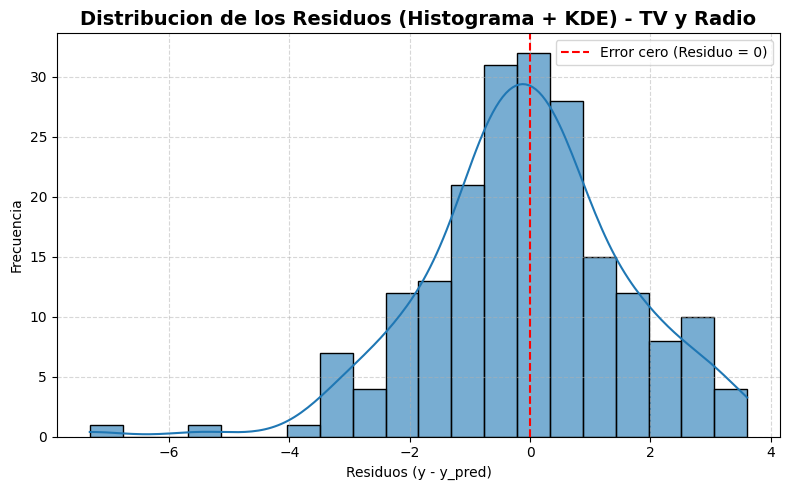

In [ ]:
# 1 Calcula los residuos: residuos = y - y_pred.
y_pred_r = modelo_r.predict(X_reducido)
residuos_r = y - y_pred_r

print("Primeros 5 residuos calculados:")
print(residuos_r.head())
print(f"\nMedia de los residuos: {residuos_r.mean():.4f}")

# 2 Grafica un histograma con KDE de los residuos.
plt.figure(figsize=(8, 5))
sns.histplot(
    residuos_r,
    kde=True,
    color='#1f77b4',
    bins=20,
    edgecolor='black',
    alpha=0.6,
)
plt.axvline(
    x=0,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Error cero (Residuo = 0)',
)
plt.title(
    'Distribucion de los Residuos (Histograma + KDE) - TV y Radio',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Residuos (y - y_pred)')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 5.2.3 ¿Los residuos parecen distribuirse normalmente?

* **Comportamiento general cercano a la normal:** Si, en su zona central los residuos muestran una distribucion aproximadamente normal con forma de campana. Estan centrados en cero con una media cercana a -0.07 y la gran mayoria de los errores se concentran entre -2 y +2 unidades de ventas.

* **Ligero sesgo negativo por valores atipicos:** Se aprecia una leve asimetria hacia la izquierda provocada por dos observaciones atipicas cercanas a -5.5 y -7, donde el modelo sobreestimo las ventas reales. No obstante, al ser casos aislados y conservar simetria en la gran mayoria de las observaciones, se cumple de forma aceptable el supuesto de normalidad.

### 5.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

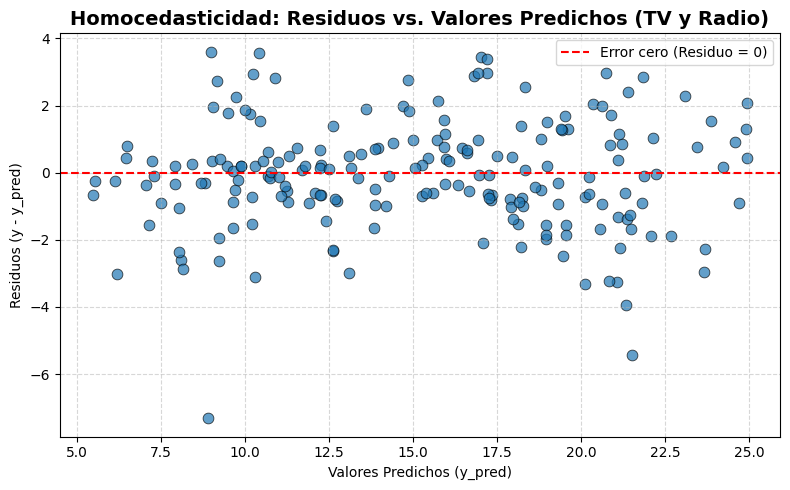

In [ ]:
# 1 Grafica los residuos contra los valores predichos.
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=y_pred_r,
    y=residuos_r,
    color='#1f77b4',
    alpha=0.7,
    edgecolor='black',
    s=60,
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Error cero (Residuo = 0)',
)

plt.title(
    'Homocedasticidad: Residuos vs. Valores Predichos (TV y Radio)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Valores Predichos (y_pred)')
plt.ylabel('Residuos (y - y_pred)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 5.3.2 ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

* **Varianza constante en la mayoria de los datos:** La dispersion de los puntos se mantiene de forma bastante uniforme dentro de una franja entre -2 y +2 alrededor de la linea roja de error cero. No se observa un patron claro de  cono, lo que indica que no hay un problema severo de heterocedasticidad



### 5.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

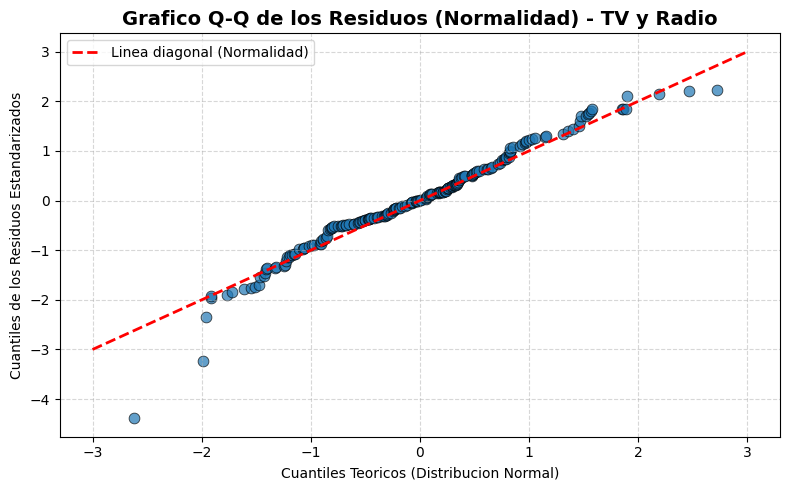

In [ ]:
# 1 Graficar el Q-Q Plot
residuos_ordenados_r = np.sort(residuos_r)
residuos_estandarizados_r = (
    residuos_ordenados_r - residuos_r.mean()
) / residuos_r.std()

np.random.seed(42)
cuantiles_teoricos_r = np.sort(np.random.normal(0, 1, len(residuos_r)))

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=cuantiles_teoricos_r,
    y=residuos_estandarizados_r,
    color='#1f77b4',
    alpha=0.7,
    edgecolor='black',
    s=60,
)
plt.plot(
    [-3, 3],
    [-3, 3],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Linea diagonal (Normalidad)',
)

plt.title(
    'Grafico Q-Q de los Residuos (Normalidad) - TV y Radio',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Cuantiles Teoricos (Distribucion Normal)')
plt.ylabel('Cuantiles de los Residuos Estandarizados')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 5.4.2 Interpreta el grafico: a) Si los puntos se alinean aproximadamente sobre la linea diagonal, los residuos siguen una distribucion normal, b) Desviaciones sistematicas indican asimetria o colas pesadas.

* **a) Alineacion sobre la linea diagonal:** Entre los valores de -2 y +2 en los cuantiles teoricos, la gran mayoria de los puntos se ubican directamente sobre la linea diagonal roja. Esto demuestra que la parte principal de los residuos sigue de forma adecuada una distribucion normal

* **b) Desviaciones en los extremos:** En la esquina inferior izquierda se aprecian dos puntos apartados hacia abajo de la diagonal (alcanzando valores cercanos a -3), mientras que en el extremo superior derecho la curva se aplana ligeramente arriba de +2. Esto confirma la presencia de una leve asimetria negativa por observaciones atipicas aisladas donde el modelo sobreestimo las ventas

### 5.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [ ]:
# 1 Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)
mse_r = mean_squared_error(y, y_pred_r)
rmse_r = np.sqrt(mse_r)
r2_r = r2_score(y, y_pred_r)

print("Metricas de Evaluacion del Modelo Simplificado (TV y Radio):")
print(f"a) MSE (Error Cuadratico Medio): {mse_r:.4f}")
print(f"b) RMSE (Raiz del Error Cuadratico Medio): {rmse_r:.4f}")
print(
    f"c) R2 (Coeficiente de Determinacion): {r2_r:.4f} ({r2_r * 100:.2f}% de"
    " varianza explicada)"
)

Metricas de Evaluacion del Modelo Simplificado (TV y Radio):
a) MSE (Error Cuadratico Medio): 2.7155
b) RMSE (Raiz del Error Cuadratico Medio): 1.6479
c) R2 (Coeficiente de Determinacion): 0.9022 (90.22% de varianza explicada)


### 5.5.2 ¿Que nos dicen estas metricas sobre el ajuste del modelo?

* **Alto poder explicativo (R2 cercano a 0.90):** El coeficiente de determinacion muestra que el modelo que utiliza unicamente TV y Radio logra explicar alrededor del 90% de la variabilidad total en las ventas. Esto demuestra que retirar la publicidad en periodico no disminuyo la capacidad explicativa global del modelo.

* **Precision del error de prediccion (MSE y RMSE):** El MSE (alrededor de 2.7) y el RMSE (alrededor de 1.64) se mantienen en valores practicamente identicos a los del modelo con tres variables. Considerando que las ventas promedio se ubican cerca de 15 unidades, equivocarse en promedio por mas o menos 1.64 unidades confirma que el modelo conserva una alta precision con una estructura mas simple y eficiente

### 5.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

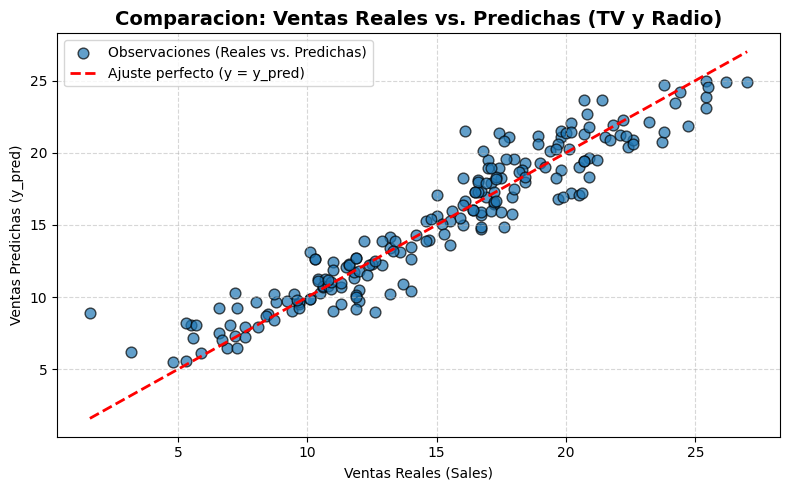

In [ ]:
# 1 Crea un gráfico comparando Sales reales vs Sales predichas
plt.figure(figsize=(8, 5))
plt.scatter(
    y,
    y_pred_r,
    color='#1f77b4',
    alpha=0.7,
    edgecolors='black',
    s=60,
    label='Observaciones (Reales vs. Predichas)',
)

lim_min_r = min(y.min(), y_pred_r.min())
lim_max_r = max(y.max(), y_pred_r.max())
plt.plot(
    [lim_min_r, lim_max_r],
    [lim_min_r, lim_max_r],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Ajuste perfecto (y = y_pred)',
)

plt.title(
    'Comparacion: Ventas Reales vs. Predichas (TV y Radio)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Ventas Reales (Sales)')
plt.ylabel('Ventas Predichas (y_pred)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 5.6.3 ¿Que observas? ¿Que informacion puedes obtener de esta grafica?

* **Ajuste lineal solido y consistente:** La mayor parte de los puntos azules se concentran estrechamente sobre la linea diagonal roja punteada de ajuste perfecto, sobre todo en el intervalo central entre 5 y 24 unidades. Esto confirma de manera visual el desempeno predictivo del modelo al utilizar unicamente TV y Radio.

* **Presencia de valores atipicos en ventas bajas:** En la esquina inferior izquierda se aprecian las dos observaciones atipicas ya detectadas anteriormente. Estos puntos se ubican por encima de la diagonal roja, reflejando una sobreestimacion puntual.

* **Eficiencia del modelo reducido:** La distribucion general de los puntos es practicamente identica a la obtenida con las tres variables en la Parte 4. Esto comprueba que retirar la inversion en periodico no genero ninguna perdida de precision en las predicciones, permitiendo trabajar con un modelo mas simple y confiable.

### 5.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [ ]:
# 1 Ajusta el modelo usando statsmodels sin Newspaper
X_train_sm_r = add_constant(X_train_r)
modelo_sm_r = sm.OLS(y_train, X_train_sm_r).fit()
print(modelo_sm_r.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                     705.7
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           3.43e-79
Time:                        03:13:19   Log-Likelihood:                -305.98
No. Observations:                 160   AIC:                             618.0
Df Residuals:                     157   BIC:                             627.2
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.7914      0.328     14.606      0.0

### 5.7.2 ¿Que variables tienen p-value menores a 0.05?
### 5.7.3 ¿Cual es la conclusion sobre esas variables?

* **Variables con p-value menor a 0.05:** Todas las variables presentes en este modelo simplificado tienen un valor p menor a 0.05. Tanto el término constante  como TV y Radio registran un p-value de 0.000

* **Conclusion sobre las variables:** Al ser los valores p menores al umbral de 0.05, se rechaza la hipotesis nula para cada coeficiente con un nivel de confianza superior al 99.9%. Esto demuestra que la inversion tanto en TV como en Radio genera un efecto estadisticamente significativo en el aumento de las ventas

* **Balance final frente al modelo anterior:** Al haber descartado la variable Newspaper (que en la Parte 4 tenia un p-value no significativo de 0.537), este nuevo modelo se compone exclusivamente de predictores relevantes, logrando un modelo final robusto y confiable

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

### Conclusion parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal)

* **Misma variable identificada para descarte:** En el analisis exploratorio previo (Parte 2.1), la unica variable que demostro carecer de una relacion lineal clara con las ventas fue Newspaper

* **Identidad con el modelo de la Parte 5:** Dicha variable (Newspaper) ya fue eliminada en la seccion anterior. En consecuencia, el conjunto de predictores resultante para esta seccion vuelve a ser exactamente TV y Radio

* **Conclusion final:** El modelo evaluado en la Parte 5 ya representa el modelo optimo sin variables no lineales.

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

## Conclusiones

* **¿Cual de los tres modelos construidos fue el mejor?**
El mejor modelo fue el que solo utiliza TV y Radio (sin Newspaper). Las metricas demuestran que es superior por tres razones:
1. Explica casi lo mismo: Mantiene un R2 de 0.90 (explica el 90% del total de las ventas), igual que el modelo de tres variables
2. Mantiene el mismo margen de error: Su error promedio (RMSE) es de 1.64 unidades, exactamente igual que antes
3. Elimina datos que no son significativos: En las pruebas estadisticas, Newspaper tuvo un p-value de 0.537 (Por encima de 0.05). En cambio, en el modelo final, tanto TV como Radio tienen un p-value de 0.000, demostrando que ambas variables si son utiles y aportar valor real al modelo

* **¿Cual fue el atributo que mas influencia tiene en las ventas?**
El atributo con mayor influencia en el negocio es TV. Las metricas que lo respaldan son:
1. Correlacion muy alta: Tiene una correlacion de 0.90 con las ventas, mientras que Radio tiene 0.35 y Newspaper apenas 0.16
2. Mayor impacto en el volumen total: Aunque cada peso en Radio aporta un coeficiente de 0.1033 y en TV aporta 0.0545